# Especialização em Ciência de Dados - Turma 2018.1 - Facens
## Projeto em Ciência de Dados Trabalho 1 – Análise Exploratória 


|**Professor:**|Fernando Vieira da Silva, M.Sc.|
|-----|-----------------------------------|

|**Nome:**|José Diniz Junior            |**RA:**|183134|
|-----|-----------------------------|---|------|
|**Nome:**|Roberto Leonardo Rodrigues   |**RA:**|060235|

O objetivo deste trabalho é explorar e entender melhor as características dos dados que serão utilizados durante o Trabalho de Conclusão do Curso. Use os conhecimentos adquiridos nas disciplinas de Visualização de Dados, Estatística e Programação em Python para Ciência de Dados. Dica: aproveite essa oportunidade para tirar suas próprias dúvidas sobre os dados e conhecer melhor o problema que você escolheu estudar. Este trabalho deve ser entregue em forma de um notebook Jupyter.

# 1 - Análise dos dados

Para o presente trabalho será utilizado dois datasets, sendo eles:

DataSet: **Fotovoltaico.csv** - referente a dados da estação fotovoltaica composta por quatro paineis solares.

DataSet: **Meteorologico.csv** - referente a dados da estação meteorológica.

**NOTA**: Ambos os datasets são refetentes ao mês de setembro de 2018.  

In [1]:
import pandas as pd
import plotly.graph_objs as go
from plotly.offline import init_notebook_mode, iplot
init_notebook_mode(connected=True)
import numpy as np

import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline
matplotlib.rcParams['font.size'] = 14
matplotlib.rcParams['figure.dpi'] = 150

import seaborn as sns
from IPython.core.pylabtools import figsize
from matplotlib.ticker import FormatStrFormatter
import plotly.tools as tls

In [2]:
dfFT = pd.read_csv('Fotovoltaico.csv', encoding='utf-8')
dfFT.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 684450 entries, 0 to 684449
Data columns (total 9 columns):
data             684450 non-null object
painel           670431 non-null float64
energia_dia      669954 non-null float64
energia_ano      669954 non-null float64
energia_total    669954 non-null float64
potencia         669954 non-null float64
power_led        684450 non-null int64
solarnet_led     684450 non-null int64
solarweb_led     684450 non-null int64
dtypes: float64(5), int64(3), object(1)
memory usage: 47.0+ MB


In [3]:
dfFT.head()

,data,painel,energia_dia,energia_ano,energia_total,potencia,power_led,solarnet_led,solarweb_led
0,2018-09-30 23:58:56.970,2.0,31640.0,14760184.0,48471100.0,0.0,1,1,1
1,2018-09-30 23:58:53.120,4.0,30504.0,11202444.0,37946500.0,0.0,1,1,1
2,2018-09-30 23:58:49.283,1.0,42950.0,19280784.0,63919004.0,0.0,1,1,1
3,2018-09-30 23:58:40.173,3.0,43730.0,15342723.0,51709800.0,0.0,1,1,1
4,2018-09-30 23:58:36.377,2.0,31640.0,14760184.0,48471100.0,0.0,1,1,1


In [4]:
# Verificando dados faltantes por coluna
dfFT.isna().sum()

data                 0
painel           14019
energia_dia      14496
energia_ano      14496
energia_total    14496
potencia         14496
power_led            0
solarnet_led         0
solarweb_led         0
dtype: int64

Observado que cinco colunas (painel, energia_dia, energia_ano, energia_total, potencia) possuiam dados faltantes por falta de medição (inxistência de valores ou somente informação com o valor do dado da coluna painel), com isso optou-se por remover essas linhas com registros faltantes, alguns casos, até foi registrado qual foi o painel mas sem registro de outras informações, sendo assim, dados irrelevantes.

In [5]:
#Removendo registros com dados faltantes
dfFT.dropna(inplace=True)
#Verificando novamente se há dados faltantes
dfFT.isna().sum()

data             0
painel           0
energia_dia      0
energia_ano      0
energia_total    0
potencia         0
power_led        0
solarnet_led     0
solarweb_led     0
dtype: int64

In [6]:
# Verificando dados com valores zero
dfFT.isin({0}).sum()

data                  0
painel                0
energia_dia      174617
energia_ano           0
energia_total         0
potencia         350949
power_led           302
solarnet_led        302
solarweb_led        302
dtype: int64

Valores com zero são aceitváveis pois em determinados períodos do dia não ocorre radiação solar sobre os paineis e com isso é aceitável determinado valor.

In [7]:
#Verificando se existem campos com valores negativos 
print((dfFT < 0).sum().drop('data'))

painel           0
energia_dia      0
energia_ano      0
energia_total    0
potencia         0
power_led        0
solarnet_led     0
solarweb_led     0
dtype: int64


In [8]:
# Removendo campos desnecessários no dataset
dfFT.drop('power_led',axis=1, inplace=True)
dfFT.drop('solarnet_led',axis=1, inplace=True)
dfFT.drop('solarweb_led',axis=1, inplace=True)

In [9]:
# Gerando mais campos a partir do campo data
dfFT['hora'] = pd.to_datetime(dfFT['data']).dt.hour
dfFT['dia'] = pd.to_datetime(dfFT['data']).dt.day

In [10]:
#Verificando a faixa de valores das colunas
dfFT.describe()

,painel,energia_dia,energia_ano,energia_total,potencia,hora,dia
count,669954.000000,669954.000000,6.699540e+05,6.699540e+05,669954.000000,669954.000000,669954.000000
mean,2.499973,24054.271769,1.434321e+07,4.970747e+07,2300.205275,11.411619,15.610870
std,1.118334,24335.027877,2.760229e+06,9.130962e+06,3652.541291,6.958309,8.639507
min,1.000000,0.000000,9.974486e+06,3.671850e+07,0.000000,0.000000,1.000000
25%,1.000000,0.000000,1.120244e+07,3.794650e+07,0.000000,5.000000,8.000000
50%,2.000000,16735.000000,1.425701e+07,4.847110e+07,0.000000,11.000000,16.000000
75%,4.000000,45940.000000,1.719769e+07,6.183590e+07,3647.000000,17.000000,23.000000
max,4.000000,79350.000000,1.928078e+07,6.391900e+07,20256.000000,23.000000,30.000000


In [11]:
dfMT = pd.read_csv('Meteorologia.csv', encoding='utf-8')
dfMT.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4297 entries, 0 to 4296
Data columns (total 15 columns):
data                       4297 non-null object
deficit_vapor_vmin         4297 non-null float64
deficit_vapor_vmedio       4297 non-null float64
ponto_orvalho_vmin         4297 non-null float64
ponto_orvalho_vmedio       4297 non-null float64
precipitacao_valor         4297 non-null float64
radiacao_solar_valor       4297 non-null float64
temperatura_ar_vmin        4297 non-null float64
temperatura_ar_vmedio      4297 non-null float64
temperatura_ar_vmax        4297 non-null float64
umidade_ar_vmin            4297 non-null float64
umidade_ar_vmedio          4297 non-null float64
umidade_ar_vmax            4297 non-null float64
velocidade_vento_vmedio    4297 non-null float64
velocidade_vento_vmax      4297 non-null float64
dtypes: float64(14), object(1)
memory usage: 503.6+ KB


In [12]:
dfMT.head()

,data,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
0,2018-09-30 23:50:06.000,0.25,0.25,18.9,18.9,0.0,0.0,20.79,20.80,20.82,89.38,89.56,89.74,0.0,0.0
1,2018-09-30 23:40:07.000,0.26,0.26,19.0,19.0,0.0,0.0,20.87,20.93,21.00,88.80,88.94,89.08,0.2,0.5
2,2018-09-30 23:30:06.000,0.27,0.27,19.0,19.0,0.0,0.0,20.98,21.00,21.02,88.95,88.99,89.03,0.0,0.1
3,2018-09-30 23:20:07.000,0.27,0.27,19.1,19.1,0.0,0.0,21.06,21.06,21.07,88.88,89.00,89.13,0.0,0.1
4,2018-09-30 23:10:06.000,0.25,0.25,19.1,19.1,0.0,0.0,20.91,20.94,20.97,89.47,89.66,89.85,0.0,0.0


In [13]:
# Verificando dados faltantes por coluna
dfMT.isna().sum()

data                       0
deficit_vapor_vmin         0
deficit_vapor_vmedio       0
ponto_orvalho_vmin         0
ponto_orvalho_vmedio       0
precipitacao_valor         0
radiacao_solar_valor       0
temperatura_ar_vmin        0
temperatura_ar_vmedio      0
temperatura_ar_vmax        0
umidade_ar_vmin            0
umidade_ar_vmedio          0
umidade_ar_vmax            0
velocidade_vento_vmedio    0
velocidade_vento_vmax      0
dtype: int64

In [14]:
# Dados com valor zero por coluna
dfMT.isin({0}).sum()

data                          0
deficit_vapor_vmin            0
deficit_vapor_vmedio          0
ponto_orvalho_vmin            0
ponto_orvalho_vmedio          0
precipitacao_valor         4147
radiacao_solar_valor       2405
temperatura_ar_vmin           0
temperatura_ar_vmedio         0
temperatura_ar_vmax           0
umidade_ar_vmin               0
umidade_ar_vmedio             0
umidade_ar_vmax               0
velocidade_vento_vmedio    1610
velocidade_vento_vmax      1409
dtype: int64

Identificado que existem colunas com valores zero, porém, foi considerado aceitável visto que são medidas momentâneas, podendo variar ao decorrer de um dia.

In [15]:
#Verificando a faixa de valores das colunas
dfMT.describe()

,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax
count,4297.000000,4297.000000,4297.000000,4297.000000,4297.000000,4297.000000,4297.000000,4297.000000,4297.000000,4297.000000,4297.000000,4297.000000,4297.000000,4297.000000
mean,0.897098,0.912234,13.781941,13.871841,0.021131,160.484524,20.504631,20.597866,20.695986,68.827389,69.273230,69.724329,0.461089,0.554689
std,0.873278,0.887208,3.273901,3.245847,0.183947,253.018622,5.225928,5.262248,5.300486,19.414074,19.229212,19.057480,0.558024,0.614450
min,0.050000,0.050000,2.900000,3.400000,0.000000,0.000000,9.810000,9.850000,9.890000,14.180000,15.560000,15.690000,0.000000,0.000000
25%,0.280000,0.290000,11.200000,11.300000,0.000000,0.000000,16.970000,17.020000,17.100000,55.770000,56.520000,57.270000,0.000000,0.000000
50%,0.540000,0.550000,13.800000,13.900000,0.000000,0.000000,19.430000,19.500000,19.580000,73.460000,73.830000,74.250000,0.200000,0.400000
75%,1.220000,1.240000,16.800000,16.800000,0.000000,250.000000,24.150000,24.300000,24.450000,84.200000,84.500000,84.810000,0.800000,0.900000
max,4.720000,4.790000,20.000000,21.000000,7.800000,963.000000,35.450000,35.470000,35.690000,96.480000,96.480000,96.480000,3.100000,3.800000


In [16]:
#Verificando se existem campos com valores negativos 
print((dfMT < 0).sum().drop('data'))

deficit_vapor_vmin         0
deficit_vapor_vmedio       0
ponto_orvalho_vmin         0
ponto_orvalho_vmedio       0
precipitacao_valor         0
radiacao_solar_valor       0
temperatura_ar_vmin        0
temperatura_ar_vmedio      0
temperatura_ar_vmax        0
umidade_ar_vmin            0
umidade_ar_vmedio          0
umidade_ar_vmax            0
velocidade_vento_vmedio    0
velocidade_vento_vmax      0
dtype: int64


In [17]:
#gerando mais campos a partir do campo data
dfMT['hora'] = pd.to_datetime(dfMT['data']).dt.hour
dfMT['dia'] = pd.to_datetime(dfMT['data']).dt.day
dfMT['minuto'] = pd.to_datetime(dfMT['data']).dt.minute

In [18]:
temp = pd.DataFrame(dfMT.groupby('dia').temperatura_ar_vmedio.mean()).reset_index()

## Gráfico da temperatura média por dia no mês de setembro

In [19]:
trace1 = go.Scatter(
                    x = temp['dia'],
                    y = temp['temperatura_ar_vmedio'],
                    mode = 'lines+markers')


data = [trace1]
layout = dict(title = 'Temperatura por dia',
              xaxis= dict(title= 'Dia',zeroline= False,
                         ticks='outside'),
              yaxis = dict(title= 'Temperatura °C',
                            ticks='outside'
                          )
             )
fig = dict(data = data, layout = layout)
iplot(fig)

2 – Liste as principais dúvidas sobre os dados (pelo menos 5). Seja específico e faça perguntas que possam te ajudar a escolher quais campos serão úteis e podem te ajudar a ter ideias de como montar sua solução no futuro. Também faça perguntas que te ajudem a identificar campos irrelevantes e que devem ser descartadas no futuro. Questões simples como “Qual a média/variância/desvio padrão do campo X?” não serão aceitas, mas perceba que pode ser interessante realizar esses cálculos para ter respostas de questões mais elaboradas. Você também pode elaborar uma questão como essa, desde faça esses cálculos para todos os campos, por exemplo: “Qual é a média, variância e desvio padrão de cada campo numérico do dataset?”  (2 pontos). 

# 2 - Principais dúvidas sobre o trabalho


1 - Qual a relação entre a radição solar com a geração de potência?

2 - Qual a energia gerada por painel fotovoltáico por dia?

3 - É possível determinar qual o período do dia a geração de energia é mais eficiente?

4 - O que a umidade do ar pode interferir na geração de energia?

5 - Qual a temperatura ideal para alcançar a potência máxima do painel?

# 3 - Gráficos 

In [84]:
trace1 = pd.DataFrame(dfMT.groupby(['dia','hora']).temperatura_ar_vmedio.mean()).reset_index()
trace2 = pd.DataFrame(dfFT.groupby(['dia','hora']).potencia.mean()).reset_index()

In [85]:
result = pd.merge(trace1,trace2,how='inner',on=['dia','hora'])

In [86]:
rad_pot = pd.DataFrame(result)

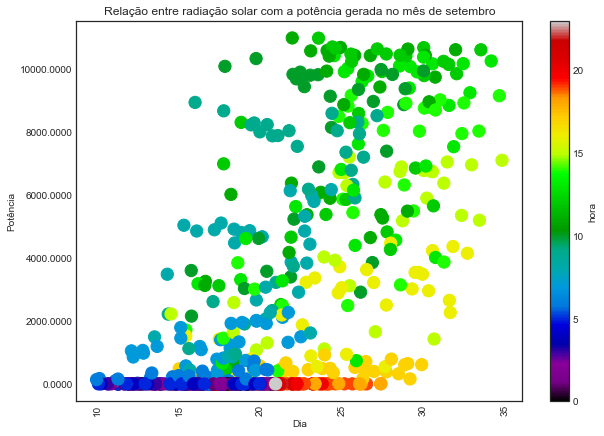

In [94]:
figsize(10,7);
fig, ax = plt.subplots(); 
ax.yaxis.set_major_formatter(FormatStrFormatter('%.4f'));
rad_pot.plot(kind="scatter", x='temperatura_ar_vmedio', y='potencia', 
                   c='hora', s=150, cmap="nipy_spectral", ax=ax,rot=90);
plt.xlabel('Dia');
plt.ylabel('Potência');
plt.title('Relação entre radiação solar com a potência gerada no mês de setembro');
plt.show()

### 1 - Qual a relação entre a radição solar com a geração de potência?

In [24]:
trace1 = pd.DataFrame(dfMT.groupby('dia').radiacao_solar_valor.mean())
trace2 = pd.DataFrame(dfFT.groupby('dia').potencia.mean())

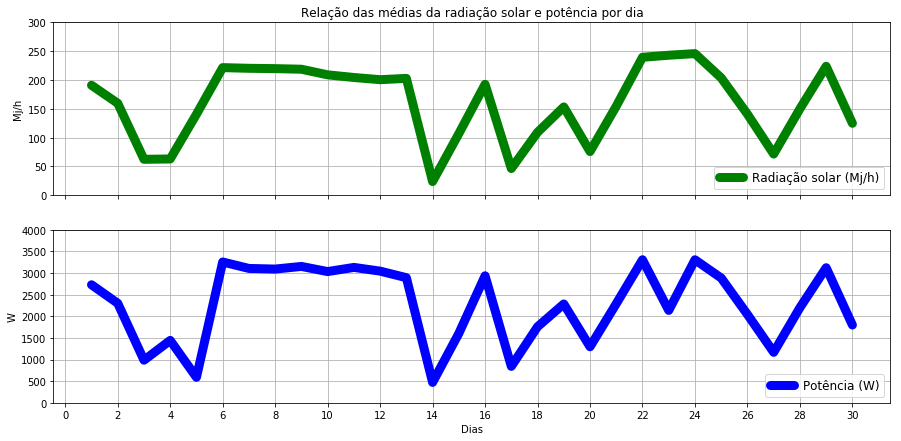

In [25]:
figsize(15,7)
f, (ax0, ax1) = plt.subplots(2, sharex=True, sharey=False)
ax0.set_title('Relação das médias da radiação solar e potência por dia')
ax0.plot(trace1 , color='green', linewidth=9, solid_capstyle="round")
ax0.set_ylim(0,300)
ax0.legend(('Radiação solar (Mj/h)',),loc='lower right', prop={'size': 12})
ax0.set_ylabel('Mj/h')
ax0.grid()
ax1.plot(trace2 , color='blue', linewidth=9, solid_capstyle="round")
ax1.legend(('Potência (W)',),loc='lower right', prop={'size': 12})
ax1.set_ylabel('W')
ax1.set_xlabel('Dias')
ax1.set_ylim(0,4000)
ax1.grid()
plt.xticks(np.arange(0, trace2.reset_index()['dia'].max()+1, step=2))
plt.setp([a.get_xticklabels() for a in f.axes[:-1]], visible=False)
plt.show()

### 2 - Qual a energia gerada por painel fotovoltáico por dia?

In [26]:
trace1 = dfFT.groupby(['painel','dia']).energia_dia.first().reset_index(name='total')

In [29]:
sctt = []
for srv in range(1,5,1):
    subset = trace1[trace1['painel'] == float(srv)];
    sctt.append(go.Scatter(
                    x = subset['dia'],
                    y = subset['total'],
                    name = srv,
                    mode = 'lines+markers')
               )

data = sctt
layout = dict(title = 'Energia diária por painel',
              xaxis= dict(title= 'Dia',zeroline= False,
                         ticks='outside'),
              yaxis = dict(title= 'Energia',
                            ticks='outside')
             )
fig = dict(data = data, layout = layout)
iplot(fig)

### 3 - É possível determinar qual o período do dia a geração de energia é mais eficiente?

In [30]:
trace1 = dfFT.groupby('hora').potencia.max().reset_index()

In [31]:
trace = go.Bar(x=trace1['hora'],y=trace1['potencia'])
data = [trace]
layout = go.Layout(
    title='Potência máxima gerada por hora',titlefont=dict(size=25),
    xaxis=dict(title='Hora',titlefont=dict(size=20)),
    yaxis=dict(title='Potência (w)',titlefont=dict(size=20)))
iplot(go.Figure(data = [trace], layout=layout))

### 4 - O que a umidade do ar pode interferir na geração de energia?

In [45]:
umi = dfMT.groupby('dia').umidade_ar_vmedio.mean().reset_index()
pot = dfFT.groupby('dia').potencia.mean().reset_index()

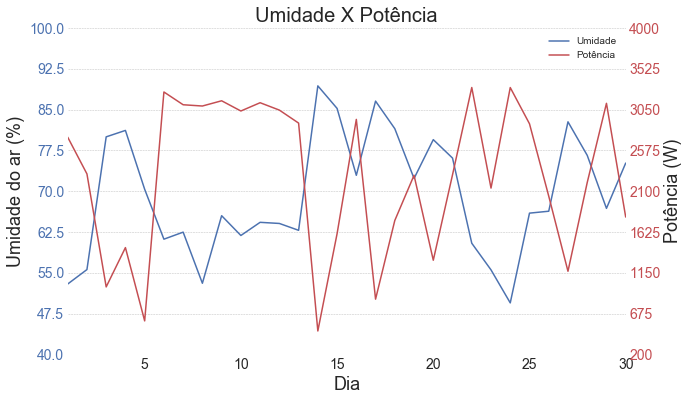

In [48]:
sns.set_style("white")  
sns.set_color_codes()

x_values = umi.dia
y_values_1 = umi.umidade_ar_vmedio

fig, ax1 = plt.subplots(figsize=(10,6))  
title = ('Umidade X Potência')

plt.title(title, fontsize=20)
plt.grid(axis='y',color='grey', linestyle='--', lw=0.5, alpha=0.5)
plt.tick_params(axis='both', labelsize=14)

plot1 = ax1.plot(x_values, y_values_1, 'b', label='Umidade')
ax1.set_ylabel('Umidade do ar (%)', fontsize=18)
ax1.set_xlabel('Dia', fontsize=18)
ax1.set_ylim(40, 100)
for tl in ax1.get_yticklabels():
    tl.set_color('b')

ax2 = ax1.twinx()
y_values_2 = pot.potencia
plot2 = ax2.plot(x_values, y_values_2, 'r', 
                 label='Potência')

ax2.set_ylabel('Potência (W)', fontsize=18)
ax2.set_ylim(200, 4000)
ax2.tick_params(axis='y', labelsize=14)
for tl in ax2.get_yticklabels():
    tl.set_color('r')

ax2.set_xlim(1, 30)
lines = plot1 + plot2

ax1.legend(lines, [l.get_label() for l in lines])
ax1.set_yticks(np.linspace(ax1.get_ybound()[0], ax1.get_ybound()[1], 9))
ax2.set_yticks(np.linspace(ax2.get_ybound()[0], ax2.get_ybound()[1], 9))

for ax in [ax1, ax2]:
    ax.spines["top"].set_visible(False)  
    ax.spines["bottom"].set_visible(False)  
    ax.spines["right"].set_visible(False)  
    ax.spines["left"].set_visible(False)  
 
plt.show()

### 5 - Em qual temperatura e radiação foi alcançado a potência máxima do painel no mês de setembro?

In [36]:
pot_max = dfFT.set_index('potencia').loc[dfFT.loc[:,{'dia','potencia'}].potencia.max()]

In [37]:
pot_max

data             2018-09-05 11:25:15.137
painel                                 1
energia_dia                        30154
energia_ano                   1.7451e+07
energia_total                6.20892e+07
hora                                  11
dia                                    5
Name: 20256.0, dtype: object

In [38]:
d = dfMT['dia'] == 5
h = dfMT['hora'] == 11
m20 = dfMT['minuto'] == 20
m30 = dfMT['minuto'] == 30


In [40]:
temp_pot_max = dfMT[ d & h & (m20 | m30) ]
temp_pot_max

,data,deficit_vapor_vmin,deficit_vapor_vmedio,ponto_orvalho_vmin,ponto_orvalho_vmedio,precipitacao_valor,radiacao_solar_valor,temperatura_ar_vmin,temperatura_ar_vmedio,temperatura_ar_vmax,umidade_ar_vmin,umidade_ar_vmedio,umidade_ar_vmax,velocidade_vento_vmedio,velocidade_vento_vmax,hora,dia,minuto
3656,2018-09-05 11:30:07.000,0.99,1.00,8.4,8.5,0.0,784.0,18.43,18.44,18.45,52.25,52.76,53.27,1.9,2.2,11,5,30
3657,2018-09-05 11:20:06.000,0.89,0.91,8.2,8.4,0.0,700.0,17.63,17.71,17.79,53.69,54.57,55.46,1.4,1.5,11,5,20


In [41]:
med_red = temp_pot_max.radiacao_solar_valor.mean()
med_red

742.0

In [42]:
med_temp = temp_pot_max.temperatura_ar_vmax.mean()
med_temp

18.119999999999997

In [43]:
a = pd.DataFrame(temp_pot_max['temperatura_ar_vmedio'])
a

,temperatura_ar_vmedio
3656,18.44
3657,17.71


In [44]:
trace = go.Bar(x=temp_pot_max['data'],y=temp_pot_max['temperatura_ar_vmedio'])
data = [trace]
layout = go.Layout(
    title='Temperatura média no dia da geração máxima do painel',titlefont=dict(size=25),
    xaxis=dict(title='Hora',titlefont=dict(size=20)),
    yaxis=dict(title='Potência (w)',titlefont=dict(size=20)))
iplot(go.Figure(data = [trace], layout=layout))

4 – Para cada uma das questões que você elaborou no exercício 2, escreva uma breve conclusão após as observações feitas no exercício 3. Seja realista, tome suas conclusões com base nos dados e tome cuidado para não fazer afirmações difíceis de serem suportadas pelas suas análises (2 pontos).

In [ ]:
https://www.portalsolar.com.br/folha-de-dados-do-painel-solar---o-que-voce-precisa-saber.html

## 1 - Qual a relação entre a radição solar com a geração de potência?



Conforme mostra o gráfico, existe uma total relação entre a radiação solar e a geração de potência, pois ele são diretamente proporcionais.

## 2 - Qual a energia gerada por painel fotovoltáico por dia?

In [ ]:
Este gráfico mostra a energia gerada em cada cainel no mês de setembro, como vemos, eles mantém uma certa igualdade quanto a 
geração, com exceção de um determinado dia que o painel 3 tem uma queda signoficativa na geração, que pode ter sido ou por uma 
falha ou por alguma sombra ocorrida neste dia.

## 3 - É possível determinar qual o período do dia a geração de energia é mais eficiente?

In [ ]:
Como visto no gráfico de geração máxima por hora dos quatro painéis, às 11hs a geração foi mais eficiebnte neste mês.

## 4 - O que a umidade do ar pode interferir na geração de energia?

In [ ]:
Podemos notar no gráfico que a umidade do ar e a geração de energia são inversamente proporcionais, pois quando uma aumenta,
a outra diminui.

## 5 - Em que temperatura e radiação foi alcançado a potência máxima do painel no mês de setembro?

In [ ]:
Para atingir a potência máxima dos painés, foi alcançado uma temperatura em torno de 18°C e radiação de 742Mj/h